## Hi! 

It's just a simple way to get 0.89 f1-score by retrain resnet18. Don't look at architecture of notebook, I did it hastily.

Btw, the main problem of this dataset is that there is a few images of diseases, and folders with images are stranger. For example, there is folders "Dataset_1", "Dataset_2" and "Dataset_Gabungan". D1 and D2 has some same images, but Gabungan unites them :O. 

In [1]:
import kagglehub

path = kagglehub.dataset_download(
    "gupiii/infectious-skin-disease-dataset",
    output_dir="./data",
)

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/gupiii/infectious-skin-disease-dataset


In [ ]:
import pandas as pd
from pathlib import Path

path = "./data/Dataset_2/"
data_dir = Path(path)
records = []

for folder in data_dir.iterdir():
    if not folder.is_dir():
        continue
    for image in folder.iterdir():
        if image.suffix.lower() not in [".jpg", ".jpeg", ".png", ".webp"]:
            continue
        records.append({
            "image_path": image,
            "label": folder.name
        })

df = pd.DataFrame(records)

Doing some EDA

In [ ]:
print('Dataset statistics:')
print(df.shape)
print('Class distribution:')
print(df['label'].value_counts())
print('Class distribution percentage:')
print(df['label'].value_counts(normalize=True).mul(100).round(2))

Dataset statistics:
(770, 2)
Class distribution:
label
Normal        293
Monkeypox     279
Chickenpox    107
Measles        91
Name: count, dtype: int64
Class distribution percentage:
label
Normal        38.05
Monkeypox     36.23
Chickenpox    13.90
Measles       11.82
Name: proportion, dtype: float64


In [ ]:
from PIL import Image

widths = []
heights = []
modes = []

for image_path in df['image_path']:
    with Image.open(image_path) as img:
        widths.append(img.width)
        heights.append(img.height)
        modes.append(img.mode)

df['width'] = widths
df['height'] = heights
df['mode'] = modes

print('Image statistics:')
print(df.describe())
print('Image distribution:')
print(df['mode'].value_counts())

Image statistics:
       width  height
count  770.0   770.0
mean   224.0   224.0
std      0.0     0.0
min    224.0   224.0
25%    224.0   224.0
50%    224.0   224.0
75%    224.0   224.0
max    224.0   224.0
Image distribution:
mode
RGB    770
Name: count, dtype: int64


                                    image_path      label  width  height mode
670   data/Dataset_2/Monkeypox/monkeypox57.png  Monkeypox    224     224  RGB
753   data/Dataset_2/Monkeypox/monkeypox22.png  Monkeypox    224     224  RGB
727  data/Dataset_2/Monkeypox/monkeypox187.png  Monkeypox    224     224  RGB
582   data/Dataset_2/Monkeypox/monkeypox77.png  Monkeypox    224     224  RGB


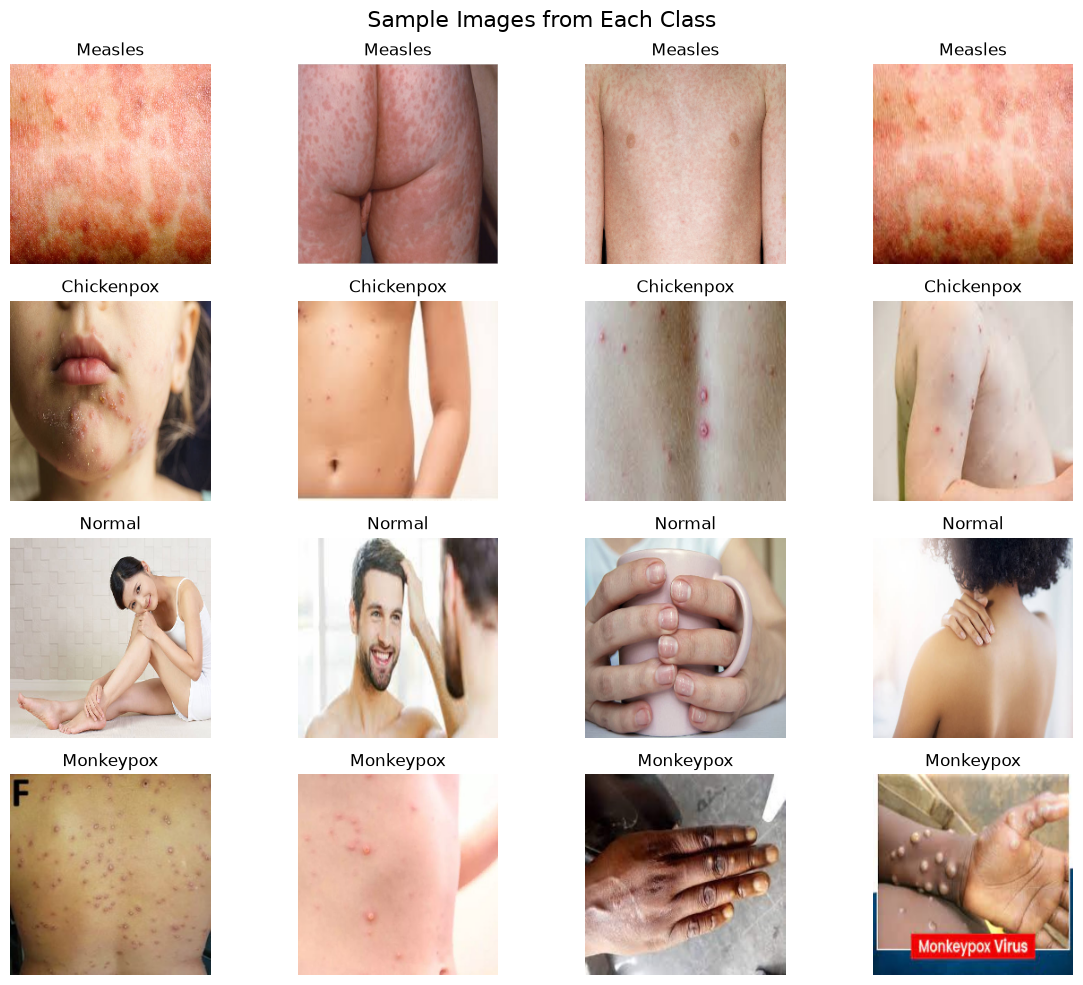

In [ ]:
import matplotlib.pyplot as plt

print(df.sample(n=4, random_state=42))

labels = df['label'].unique()
fig, axes = plt.subplots(
    nrows=len(labels),
    ncols=4,
    figsize=(12,10)
)
fig.suptitle('Sample Images from Each Class', fontsize=16)

for i, label in enumerate(labels):
    sample = df[df['label'] == label].sample(n=4, random_state=42)
    for j, (_, row) in enumerate(sample.iterrows()):
        img = Image.open(row['image_path'])
        axes[i, j].imshow(img)
        axes[i, j].set_title(f'{label}')
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

We can see that some images very similar between different diseases. In particular Monkeypox looks like Chickenpox. This is the main problem of this task

We must clean dubplicates from this dataset

In [6]:
labels = df['label'].unique()
class_to_idx = {
    "Chickenpox": 0,
    "Measles": 1,
    "Monkeypox": 2,
    "Normal": 3,
}
df['target'] = df['label'].map(class_to_idx)
print(df.head())

                             image_path    label  width  height mode  target
0  data/Dataset_2/Measles/measles74.png  Measles    224     224  RGB       1
1  data/Dataset_2/Measles/measles60.png  Measles    224     224  RGB       1
2  data/Dataset_2/Measles/measles48.png  Measles    224     224  RGB       1
3   data/Dataset_2/Measles/measles9.png  Measles    224     224  RGB       1
4   data/Dataset_2/Measles/measles8.png  Measles    224     224  RGB       1


In [ ]:
import hashlib

hashes = []

for image_path in df['image_path']:
    img_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()
    hashes.append(img_hash)
df['hash'] = hashes

In [8]:
duplicate_mask = df['hash'].duplicated(keep=False)
print('Unique hashes:', df['hash'].nunique())
print('Duplicates count:', duplicate_mask.sum())

print('Duplicate images:', df[duplicate_mask]['image_path'].unique())

Unique hashes: 765
Duplicates count: 10
Duplicate images: [PosixPath('data/Dataset_2/Measles/measles40.png')
 PosixPath('data/Dataset_2/Measles/measles91.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox18.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox20.png')
 PosixPath('data/Dataset_2/Normal/normal54.png')
 PosixPath('data/Dataset_2/Normal/normal47.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox111.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox112.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox67.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox78.png')]


In [ ]:
df_clean = (
    df.drop_duplicates(subset=['hash'])
    .reset_index(drop=True)
    .copy()
)
print('Dataset statistics after cleaning:', df_clean.shape)
print('Class distribution after cleaning:', df_clean['label'].value_counts())
print('Class distribution percentage after cleaning:', df_clean['label'].value_counts(normalize=True).mul(100).round(2))

Dataset statistics after cleaning: (765, 7)
Class distribution after cleaning: label
Normal        292
Monkeypox     277
Chickenpox    106
Measles        90
Name: count, dtype: int64
Class distribution percentage after cleaning: label
Normal        38.17
Monkeypox     36.21
Chickenpox    13.86
Measles       11.76
Name: proportion, dtype: float64


In [ ]:
import imagehash

phashes = []

for image_path in df_clean['image_path']:
    with Image.open(image_path) as img:
        phashes.append(str(imagehash.phash(img)))
df_clean['phash'] = phashes

In [11]:
phash_duplicate_mask = df_clean['phash'].duplicated(keep=False)
print('Unique phashes:', df_clean['phash'].nunique())
print('Duplicates count:', phash_duplicate_mask.sum())


Unique phashes: 756
Duplicates count: 18


Phash duplicates: [PosixPath('data/Dataset_2/Measles/measles39.png')
 PosixPath('data/Dataset_2/Measles/measles12.png')
 PosixPath('data/Dataset_2/Measles/measles5.png')
 PosixPath('data/Dataset_2/Measles/measles79.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox22.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox78.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox94.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox65.png')
 PosixPath('data/Dataset_2/Chickenpox/chickenpox11.png')
 PosixPath('data/Dataset_2/Normal/normal15.png')
 PosixPath('data/Dataset_2/Normal/normal222.png')
 PosixPath('data/Dataset_2/Normal/normal57.png')
 PosixPath('data/Dataset_2/Normal/normal86.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox71.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox99.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox61.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox84.png')
 PosixPath('data/Dataset_2/Monkeypox/monkeypox134.png')]


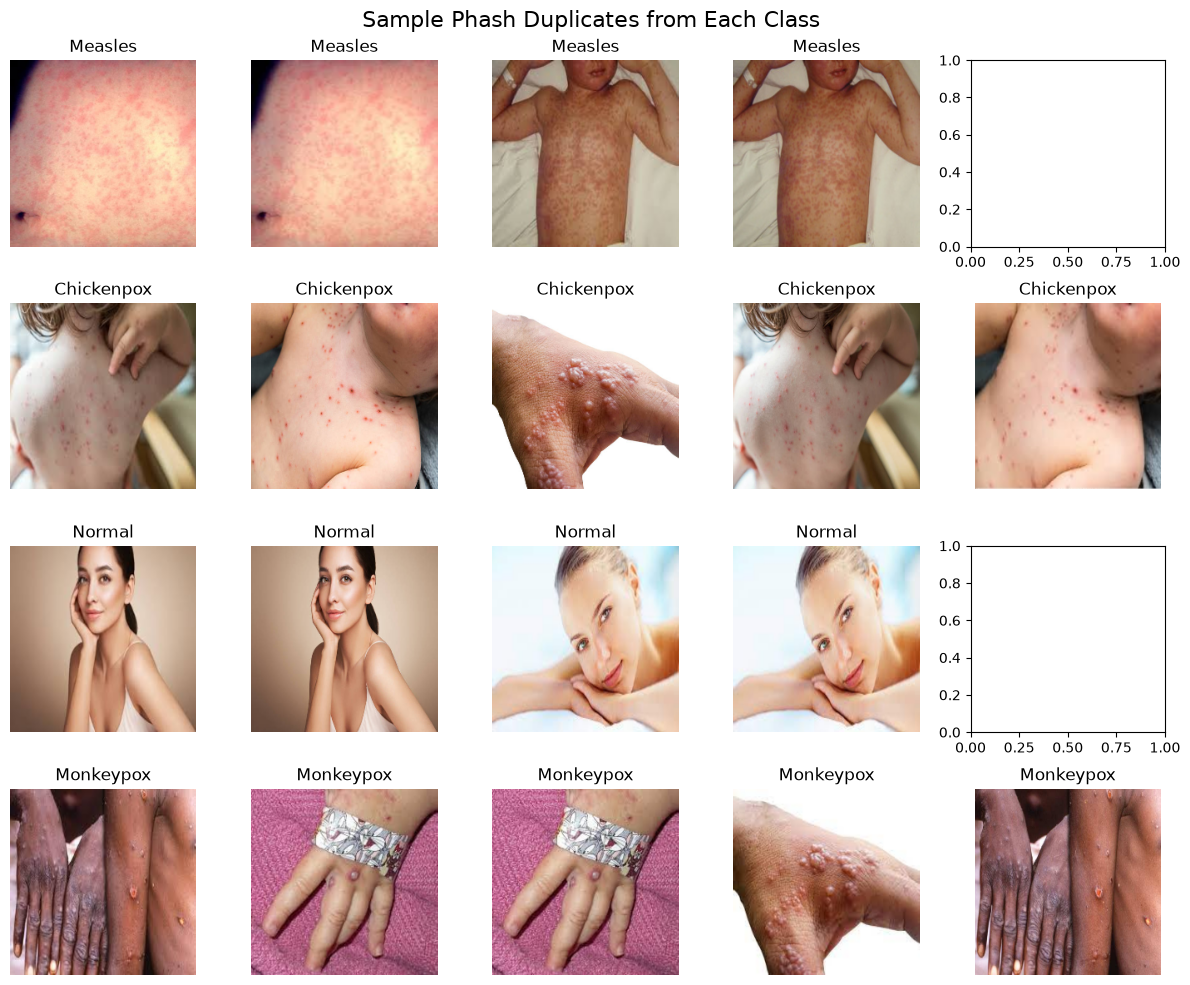

In [ ]:
phashduples = df_clean[phash_duplicate_mask]
print('Phash duplicates:', phashduples['image_path'].unique())

labels = phashduples['label'].unique()
fig, axes = plt.subplots(
    nrows=len(labels),
    ncols=5,
    figsize=(12,10)
)
fig.suptitle('Sample Phash Duplicates from Each Class', fontsize=16)

for i, label in enumerate(labels):
    sample = phashduples[phashduples['label'] == label]
    for j, (_, row) in enumerate(sample.iterrows()):
        img = Image.open(row['image_path'])
        axes[i, j].imshow(img)
        axes[i, j].set_title(f'{label}')
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
label_counts = df_clean.groupby("phash")["label"].nunique()

conflicting_phashes = label_counts[label_counts > 1].index

df_final = df_clean[
    ~df_clean["phash"].isin(conflicting_phashes)
].copy()

df_final = (
    df_final.drop_duplicates("phash", keep="first")
    .reset_index(drop=True)
)
print('Dataset statistics after cleaning:', df_final.shape)
print('Class distribution after cleaning:', df_final['label'].value_counts())
print('Class distribution percentage after cleaning:', df_final['label'].value_counts(normalize=True).mul(100).round(2))

Dataset statistics after cleaning: (755, 8)
Class distribution after cleaning: label
Normal        290
Monkeypox     274
Chickenpox    103
Measles        88
Name: count, dtype: int64
Class distribution percentage after cleaning: label
Normal        38.41
Monkeypox     36.29
Chickenpox    13.64
Measles       11.66
Name: proportion, dtype: float64


Ok, data is clear and we should go to next step

## Splitting dataset

In [ ]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df_final, test_size=0.3, random_state=42, stratify=df_final['label'])
val_df, test_df = train_test_split(test_df, test_size=0.5, random_state=42, stratify=test_df['label'])

print('Train dataset statistics:', train_df.shape)
print('Validation dataset statistics:', val_df.shape)
print('Test dataset statistics:', test_df.shape)

print('Class distribution percentage in train dataset:', train_df['label'].value_counts(normalize=True).mul(100).round(2))
print('Class distribution percentage in validation dataset:', val_df['label'].value_counts(normalize=True).mul(100).round(2))
print('Class distribution percentage in test dataset:', test_df['label'].value_counts(normalize=True).mul(100).round(2))

Train dataset statistics: (528, 8)
Validation dataset statistics: (113, 8)
Test dataset statistics: (114, 8)
Class distribution percentage in train dataset: label
Normal        38.45
Monkeypox     36.36
Chickenpox    13.64
Measles       11.55
Name: proportion, dtype: float64
Class distribution percentage in validation dataset: label
Normal        38.05
Monkeypox     36.28
Chickenpox    13.27
Measles       12.39
Name: proportion, dtype: float64
Class distribution percentage in test dataset: label
Normal        38.60
Monkeypox     35.96
Chickenpox    14.04
Measles       11.40
Name: proportion, dtype: float64


In [15]:
from torch.utils.data import Dataset
class SkinDiseaseDataset(Dataset):
    def __init__(self,dataframe,transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.dataframe)
    def __getitem__(self,index):
        row = self.dataframe.iloc[index]
        img_path = row['image_path']
        with Image.open(img_path) as image:
            img = image.convert('RGB')
        if self.transform:
            img = self.transform(img)
        target = int(row['target'])
        return img, target
        

In [16]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [ ]:
from torch.utils.data import DataLoader

train_dataset = SkinDiseaseDataset(train_df, transform=train_transform)
val_dataset = SkinDiseaseDataset(val_df, transform=eval_transform)
test_dataset = SkinDiseaseDataset(test_df, transform=eval_transform)

train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
)
val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
)
test_loader = DataLoader(
    test_dataset,
    batch_size=32, 
    shuffle=False, 
)

images, targets = next(iter(train_loader))

print('Images shape:', images.shape)
print('Targets shape:', targets.shape)
print('Images type:', images.dtype)
print('Targets type:', targets.dtype)

Images shape: torch.Size([32, 3, 224, 224])
Targets shape: torch.Size([32])
Images type: torch.float32
Targets type: torch.int64


In [ ]:
import torch
from torch import nn
from torchvision.models import resnet18

device = torch.device('mps' if torch.mps.is_available() else 'cpu')
print('Using device: ', device)

model = resnet18(weights=None)
state_dict = torch.load(
    'resnet18.pth',
    map_location = device,
    weights_only = True,
)
model.load_state_dict(state_dict)

for param in model.parameters():
    param.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, 4)
model = model.to(device)

images, targets = next(iter(train_loader))
logits = model(images.to(device))
print('Logits shape:', logits.shape)

Using device:  mps
Logits shape: torch.Size([32, 4])


Trying to train simple model 

In [ ]:
from sklearn.metrics import f1_score
import copy

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    (param for param in model.parameters() if param.requires_grad),
    lr=1e-3
)

epochs = 10
best_params = {
    'epoch': 0,
    'val_loss': 0.0,
    'val_accuracy': 0.0,
    'val_f1': -1.0,
    'model_state': None,
    'optimizer_state': None,
}

for epoch in range(epochs):
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    all_preds = []
    all_targets = []
    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)
            loss = criterion(logits, targets.long())

            val_loss += loss.item() * images.size(0)
            val_correct += (logits.argmax(dim=1) == targets).sum().item()
            val_total += targets.size(0)

            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_targets.extend(targets.cpu().tolist())
    val_loss /= val_total
    print(f'Epoch {epoch+1}/{epochs}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_correct/val_total:.4f}')
    val_f1 = f1_score(all_targets, all_preds, average='macro')
    print(f'Val F1 Score: {val_f1:.4f}')
    if val_f1 > best_params['val_f1']:
        best_params['val_loss'] = val_loss
        best_params['val_f1'] = val_f1
        best_params['epoch'] = epoch
        best_params['model_state'] = copy.deepcopy(model.state_dict())
        best_params['optimizer_state'] = copy.deepcopy(optimizer.state_dict())
        best_params['val_accuracy'] = (val_correct / val_total)
print(f'Best Val F1 Score: {best_params["val_f1"]:.4f} at Epoch {best_params["epoch"]+1}, Val Accuracy: {best_params["val_accuracy"]:.4f}')
model.load_state_dict(best_params['model_state'])
optimizer.load_state_dict(best_params['optimizer_state'])

Epoch 1/10, Val Loss: 0.8969, Val Accuracy: 0.6726
Val F1 Score: 0.4578
Epoch 2/10, Val Loss: 0.7858, Val Accuracy: 0.7257
Val F1 Score: 0.6005
Epoch 3/10, Val Loss: 0.6523, Val Accuracy: 0.7699
Val F1 Score: 0.6718
Epoch 4/10, Val Loss: 0.6115, Val Accuracy: 0.8053
Val F1 Score: 0.7384
Epoch 5/10, Val Loss: 0.5669, Val Accuracy: 0.7965
Val F1 Score: 0.7192
Epoch 6/10, Val Loss: 0.5374, Val Accuracy: 0.8142
Val F1 Score: 0.7497
Epoch 7/10, Val Loss: 0.5283, Val Accuracy: 0.8230
Val F1 Score: 0.7681
Epoch 8/10, Val Loss: 0.5299, Val Accuracy: 0.8142
Val F1 Score: 0.7546
Epoch 9/10, Val Loss: 0.4883, Val Accuracy: 0.8584
Val F1 Score: 0.8093
Epoch 10/10, Val Loss: 0.5015, Val Accuracy: 0.8407
Val F1 Score: 0.7905
Best Val F1 Score: 0.8093 at Epoch 9, Val Accuracy: 0.8584


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

class_names = ['Chickenpox', 'Measles', 'Monkeypox', 'Normal']

val_best_preds = []
val_best_targets = []

model.eval()
with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)
        val_best_preds.extend(logits.argmax(dim=1).cpu().tolist())
        val_best_targets.extend(targets.cpu().tolist())

print('Classification Report:')
print(classification_report(
    val_best_targets, 
    val_best_preds, 
    target_names=class_names,
    digits=3))
print('Confusion Matrix:')
print(confusion_matrix(val_best_targets, val_best_preds))

Classification Report:
              precision    recall  f1-score   support

  Chickenpox      0.750     0.600     0.667        15
     Measles      0.833     0.714     0.769        14
   Monkeypox      0.878     0.878     0.878        41
      Normal      0.875     0.977     0.923        43

    accuracy                          0.858       113
   macro avg      0.834     0.792     0.809       113
weighted avg      0.854     0.858     0.854       113

Confusion Matrix:
[[ 9  1  2  3]
 [ 1 10  2  1]
 [ 2  1 36  2]
 [ 0  0  1 42]]


Checking errors images. There will be 2 groups: chickenpox as normal and minkeypox as chickenpox

In [21]:
review = val_df.reset_index(drop=True).copy()
review['pred'] = [class_names[pred] for pred in val_best_preds]

print(review.head())
print(len(review), len(val_best_preds))

                                   image_path       label  width  height mode  \
0  data/Dataset_2/Chickenpox/chickenpox39.png  Chickenpox    224     224  RGB   
1  data/Dataset_2/Chickenpox/chickenpox99.png  Chickenpox    224     224  RGB   
2        data/Dataset_2/Measles/measles86.png     Measles    224     224  RGB   
3   data/Dataset_2/Monkeypox/monkeypox173.png   Monkeypox    224     224  RGB   
4        data/Dataset_2/Measles/measles38.png     Measles    224     224  RGB   

   target                                               hash  \
0       0  71e8465da3d0af04ea858c29d4b1767e391fdb2e8090b8...   
1       0  f3ac73b84f0431837095fb0c120a9c59682d81c0acd9f0...   
2       1  a29ca2874723e68be45db86c41d0cfa40551f610f2157f...   
3       2  eeae22054c7572cde62c0e753f0f5feb191ffae7f9cc6d...   
4       1  e869ae7f8d00ca205a6626838f4c039bfc365c0ca56854...   

              phash        pred  
0  b6c42e303c99cf8b      Normal  
1  efa061a5e587a594     Measles  
2  c0646faf44963cba     Me

In [22]:
chickenpox_as_normal = review[
    (review['pred'] == 'Normal') 
    & (review['label'] == 'Chickenpox')
]
monkeypox_as_chickenpox = review[
    (review['pred'] == 'Chickenpox') 
    & (review['label'] == 'Monkeypox')
]
print('Chickenpox as normal:', len(chickenpox_as_normal))
print('Monkeypox as chickenpox:', len(monkeypox_as_chickenpox))

Chickenpox as normal: 3
Monkeypox as chickenpox: 2


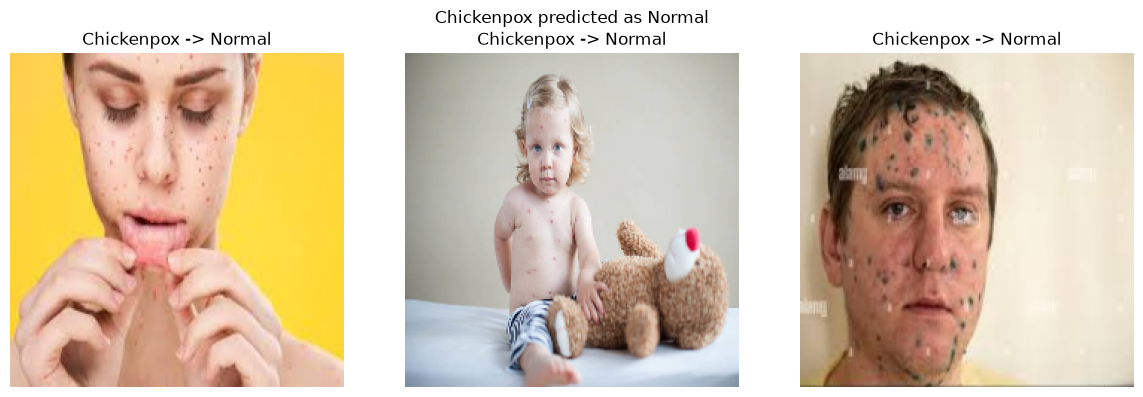

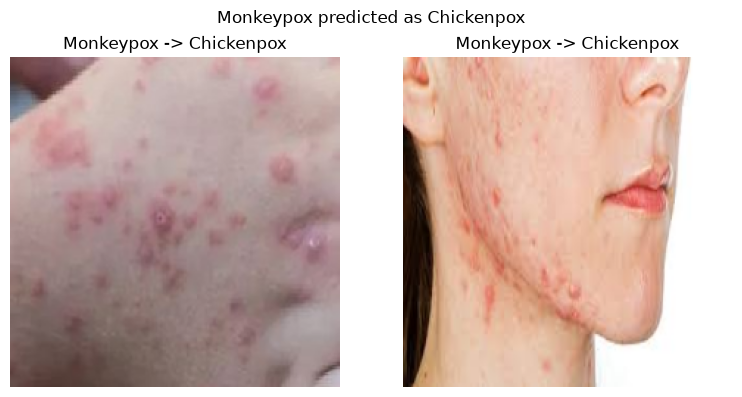

In [23]:
def show_errors(group, title):
    count = len(group)
    fig, axes = plt.subplots(1, count, figsize=(4 * count, 4))
    if count == 1:
        axes = [axes]
    for axis, (_, row) in zip(axes, group.iterrows()):
        with Image.open(row["image_path"]) as image:
            axis.imshow(image.convert("RGB"))
        axis.set_title(f'{row["label"]} -> {row["pred"]}')
        axis.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
show_errors(chickenpox_as_normal, "Chickenpox predicted as Normal")
show_errors(monkeypox_as_chickenpox, "Monkeypox predicted as Chickenpox")


Ok, we can see like I said before, Monkeypox and Chickenpox are get confused with each other because there is some similar images.

And we can see, that images with a distant angle are hard for our model.

We know that now features of ImageMet  couldn't discern diseases. And in future it may be the way to get our model better

But now let's try to count weights

Counting weights

In [26]:
model.fc = nn.Linear(model.fc.in_features, 4)
model = model.to(device)

images, targets = next(iter(train_loader))
logits = model(images.to(device))

counts = train_df['label'].value_counts()
weights = [
    len(train_df) / (len(class_names) * counts[name]) 
    for name in class_names
]

criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))

optimizer = torch.optim.Adam(
    (param for param in model.parameters() if param.requires_grad),
    lr=1e-3
)

epochs = 10
best_params = {
    'epoch': 0,
    'val_loss': 0.0,
    'val_accuracy': 0.0,
    'val_f1': -1.0,
    'model_state': None,
    'optimizer_state': None,
}

for epoch in range(epochs):
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    all_preds = []
    all_targets = []
    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)
            loss = criterion(logits, targets.long())

            val_loss += loss.item() * images.size(0)
            val_correct += (logits.argmax(dim=1) == targets).sum().item()
            val_total += targets.size(0)

            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_targets.extend(targets.cpu().tolist())
    val_loss /= val_total
    print(f'Epoch {epoch+1}/{epochs}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_correct/val_total:.4f}')
    val_f1 = f1_score(all_targets, all_preds, average='macro')
    print(f'Val F1 Score: {val_f1:.4f}')
    if val_f1 > best_params['val_f1']:
        best_params['val_loss'] = val_loss
        best_params['val_f1'] = val_f1
        best_params['epoch'] = epoch
        best_params['model_state'] = copy.deepcopy(model.state_dict())
        best_params['optimizer_state'] = copy.deepcopy(optimizer.state_dict())
        best_params['val_accuracy'] = (val_correct / val_total)
print(f'Best Val F1 Score: {best_params["val_f1"]:.4f} at Epoch {best_params["epoch"]+1}, Val Accuracy: {best_params["val_accuracy"]:.4f}')
model.load_state_dict(best_params['model_state'])
optimizer.load_state_dict(best_params['optimizer_state'])

Epoch 1/10, Val Loss: 1.0400, Val Accuracy: 0.7434
Val F1 Score: 0.6531
Epoch 2/10, Val Loss: 0.8298, Val Accuracy: 0.8053
Val F1 Score: 0.7637
Epoch 3/10, Val Loss: 0.7408, Val Accuracy: 0.8496
Val F1 Score: 0.8289
Epoch 4/10, Val Loss: 0.6725, Val Accuracy: 0.8319
Val F1 Score: 0.8027
Epoch 5/10, Val Loss: 0.6301, Val Accuracy: 0.8142
Val F1 Score: 0.7853
Epoch 6/10, Val Loss: 0.6282, Val Accuracy: 0.8673
Val F1 Score: 0.8241
Epoch 7/10, Val Loss: 0.5879, Val Accuracy: 0.8496
Val F1 Score: 0.8024
Epoch 8/10, Val Loss: 0.5956, Val Accuracy: 0.8142
Val F1 Score: 0.7744
Epoch 9/10, Val Loss: 0.5650, Val Accuracy: 0.8673
Val F1 Score: 0.8335
Epoch 10/10, Val Loss: 0.5797, Val Accuracy: 0.8319
Val F1 Score: 0.8024
Best Val F1 Score: 0.8335 at Epoch 9, Val Accuracy: 0.8673


In [ ]:
class_names = ['Chickenpox', 'Measles', 'Monkeypox', 'Normal']

val_best_preds = []
val_best_targets = []

model.eval()
with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)
        val_best_preds.extend(logits.argmax(dim=1).cpu().tolist())
        val_best_targets.extend(targets.cpu().tolist())

print('Classification Report:')
print(classification_report(
    val_best_targets, 
    val_best_preds, 
    target_names=class_names,
    digits=3))
print('Confusion Matrix:')
print(confusion_matrix(val_best_targets, val_best_preds))

Classification Report:
              precision    recall  f1-score   support

  Chickenpox      0.619     0.867     0.722        15
     Measles      0.786     0.786     0.786        14
   Monkeypox      1.000     0.829     0.907        41
      Normal      0.909     0.930     0.920        43

    accuracy                          0.867       113
   macro avg      0.828     0.853     0.834       113
weighted avg      0.888     0.867     0.872       113

Confusion Matrix:
[[13  0  0  2]
 [ 1 11  0  2]
 [ 5  2 34  0]
 [ 2  1  0 40]]


We see it works! What if we unfreeze 4 layers of ImageNet

Lets try to unfreeze layer 4 of ImageNet

In [28]:
model.fc = nn.Linear(model.fc.in_features, 4)
model = model.to(device)

images, targets = next(iter(train_loader))
logits = model(images.to(device))

counts = train_df['label'].value_counts()
weights = [
    len(train_df) / (len(class_names) * counts[name]) 
    for name in class_names
]

criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=device))

for param in model.layer4.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(
    (param for param in model.parameters() if param.requires_grad),
    lr=1e-3
)

epochs = 10
best_params = {
    'epoch': 0,
    'val_loss': 0.0,
    'val_accuracy': 0.0,
    'val_f1': -1.0,
    'model_state': None,
    'optimizer_state': None,
}

for epoch in range(epochs):
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    all_preds = []
    all_targets = []
    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)
            loss = criterion(logits, targets.long())

            val_loss += loss.item() * images.size(0)
            val_correct += (logits.argmax(dim=1) == targets).sum().item()
            val_total += targets.size(0)

            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_targets.extend(targets.cpu().tolist())
    val_loss /= val_total
    print(f'Epoch {epoch+1}/{epochs}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_correct/val_total:.4f}')
    val_f1 = f1_score(all_targets, all_preds, average='macro')
    print(f'Val F1 Score: {val_f1:.4f}')
    if val_f1 > best_params['val_f1']:
        best_params['val_loss'] = val_loss
        best_params['val_f1'] = val_f1
        best_params['epoch'] = epoch
        best_params['model_state'] = copy.deepcopy(model.state_dict())
        best_params['optimizer_state'] = copy.deepcopy(optimizer.state_dict())
        best_params['val_accuracy'] = (val_correct / val_total)
print(f'Best Val F1 Score: {best_params["val_f1"]:.4f} at Epoch {best_params["epoch"]+1}, Val Accuracy: {best_params["val_accuracy"]:.4f}')
model.load_state_dict(best_params['model_state'])
optimizer.load_state_dict(best_params['optimizer_state'])

Epoch 1/10, Val Loss: 1.4963, Val Accuracy: 0.3628
Val F1 Score: 0.1331
Epoch 2/10, Val Loss: 1.2776, Val Accuracy: 0.4425
Val F1 Score: 0.2753
Epoch 3/10, Val Loss: 0.9308, Val Accuracy: 0.6018
Val F1 Score: 0.5565
Epoch 4/10, Val Loss: 0.6299, Val Accuracy: 0.8142
Val F1 Score: 0.7380
Epoch 5/10, Val Loss: 0.9836, Val Accuracy: 0.5133
Val F1 Score: 0.4884
Epoch 6/10, Val Loss: 0.6345, Val Accuracy: 0.7611
Val F1 Score: 0.7338
Epoch 7/10, Val Loss: 0.6403, Val Accuracy: 0.7168
Val F1 Score: 0.7121
Epoch 8/10, Val Loss: 0.3713, Val Accuracy: 0.8761
Val F1 Score: 0.8577
Epoch 9/10, Val Loss: 0.4104, Val Accuracy: 0.8938
Val F1 Score: 0.8283
Epoch 10/10, Val Loss: 0.2863, Val Accuracy: 0.8850
Val F1 Score: 0.8626
Best Val F1 Score: 0.8626 at Epoch 10, Val Accuracy: 0.8850


In [29]:
class_names = ['Chickenpox', 'Measles', 'Monkeypox', 'Normal']

val_best_preds = []
val_best_targets = []

model.eval()
with torch.no_grad():
    for images, targets in val_loader:
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)
        val_best_preds.extend(logits.argmax(dim=1).cpu().tolist())
        val_best_targets.extend(targets.cpu().tolist())

print('Classification Report:')
print(classification_report(
    val_best_targets, 
    val_best_preds, 
    target_names=class_names,
    digits=3))
print('Confusion Matrix:')
print(confusion_matrix(val_best_targets, val_best_preds))

Classification Report:
              precision    recall  f1-score   support

  Chickenpox      0.800     0.800     0.800        15
     Measles      0.700     1.000     0.824        14
   Monkeypox      0.972     0.854     0.909        41
      Normal      0.929     0.907     0.918        43

    accuracy                          0.885       113
   macro avg      0.850     0.890     0.863       113
weighted avg      0.899     0.885     0.887       113

Confusion Matrix:
[[12  1  1  1]
 [ 0 14  0  0]
 [ 1  3 35  2]
 [ 2  2  0 39]]


Get more epochs

In [ ]:
epochs = 5
edited = False
for epoch in range(epochs):
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    all_preds = []
    all_targets = []
    for images, targets in train_loader:
        images = images.to(device)
        targets = targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = targets.to(device)

            logits = model(images)
            loss = criterion(logits, targets.long())

            val_loss += loss.item() * images.size(0)
            val_correct += (logits.argmax(dim=1) == targets).sum().item()
            val_total += targets.size(0)

            all_preds.extend(logits.argmax(dim=1).cpu().tolist())
            all_targets.extend(targets.cpu().tolist())
    val_loss /= val_total
    print(f'Epoch {epoch+1}/{epochs}, Val Loss: {val_loss:.4f}, Val Accuracy: {val_correct/val_total:.4f}')
    val_f1 = f1_score(all_targets, all_preds, average='macro')
    print(f'Val F1 Score: {val_f1:.4f}')
    if val_f1 > best_params['val_f1']:
        edited = True
        best_params['val_loss'] = val_loss
        best_params['val_f1'] = val_f1
        best_params['epoch'] = epoch
        best_params['model_state'] = copy.deepcopy(model.state_dict())
        best_params['optimizer_state'] = copy.deepcopy(optimizer.state_dict())
        best_params['val_accuracy'] = (val_correct / val_total)
model.load_state_dict(best_params["model_state"])
if edited:
    print(f'Model was edited. Best Val F1 Score: {best_params["val_f1"]:.4f} at Epoch {best_params["epoch"]+1}, Val Accuracy: {best_params["val_accuracy"]:.4f}')
else:
    print('Model was not edited')


Epoch 1/5, Val Loss: 0.3194, Val Accuracy: 0.9115
Val F1 Score: 0.8811
Epoch 2/5, Val Loss: 0.3207, Val Accuracy: 0.9027
Val F1 Score: 0.8774
Epoch 3/5, Val Loss: 0.3357, Val Accuracy: 0.9204
Val F1 Score: 0.8953
Epoch 4/5, Val Loss: 0.2800, Val Accuracy: 0.9204
Val F1 Score: 0.9070
Epoch 5/5, Val Loss: 0.2864, Val Accuracy: 0.9204
Val F1 Score: 0.9070
Model was edited. Best Val F1 Score: {best_params["val_f1"]:.4f} at Epoch {best_params["epoch"]+1}, Val Accuracy: {best_params["val_accuracy"]:.4f}


In [ ]:
if edited:
    print(f'Model was edited. Best Val F1 Score: {best_params["val_f1"]:.4f} at Epoch {best_params["epoch"]+1}, Val Accuracy: {best_params["val_accuracy"]:.4f}')
else:
    print('Model was not edited')


Model was edited. Best Val F1 Score: 0.9070 at Epoch 4, Val Accuracy: 0.9204


Good val F1 score is 0.90 lets check test 

In [32]:
from sklearn.metrics import accuracy_score

test_preds = []
test_targets = []

model.eval()
with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)

        test_preds.extend(logits.argmax(dim=1).cpu().tolist())
        test_targets.extend(targets.cpu().tolist())
accuracy_test = accuracy_score(test_targets, test_preds)
f1_test = f1_score(test_targets, test_preds, average='macro')
print(classification_report(
    test_targets,
    test_preds,
    target_names=class_names,
    digits=3,
))
print(confusion_matrix(test_targets, test_preds))
print(f'Test Accuracy: {accuracy_test:.4f}')
print(f'Test F1 Score: {f1_test:.4f}')

              precision    recall  f1-score   support

  Chickenpox      0.833     0.938     0.882        16
     Measles      0.909     0.769     0.833        13
   Monkeypox      0.923     0.878     0.900        41
      Normal      0.935     0.977     0.956        44

    accuracy                          0.912       114
   macro avg      0.900     0.891     0.893       114
weighted avg      0.913     0.912     0.911       114

[[15  0  1  0]
 [ 0 10  2  1]
 [ 2  1 36  2]
 [ 1  0  0 43]]
Test Accuracy: 0.9123
Test F1 Score: 0.8928


In fact, it’s difficult to improve this model on the test for higher metrics. The dataset is too small for such a task, and there’s confusion between some diseases. Even I, as a human, can’t tell the diseases apart. For such tasks, a larger number of images is required to identify the distinctive features of each disease.

## Good luck